# Q3 — Decimal (slot) signal inside anchor neighborhoods: low blocks

From `num_grid_eda.md` (Q3). Question: conditioned on an anchor — the
neighborhood [anchor, anchor+1) — is a row's fraud risk related to its
slot, i.e. its decimal position within the neighborhood?

Scope (agreed after Q1):

- **Columns**: velocity_score and merchant_risk_score only. Both sit on a
  0.1 grid, so each neighborhood has exactly 10 slot positions (.0 - .9).
- **Blocks**: the resolved low blocks from the Q1 check — velocity
  anchors <= 40, risk anchors <= 55 — where anchor rates are stable and
  row counts are large (best statistical power for a small conditional
  effect). Anchors inside the block with < 50 frauds are excluded
  (threshold from `num_grid_eda.md` Q3).
- **Machinery**: identical to Q1 — the frozen unified alarm-profile
  5-fold split; per-cell (anchor, slot) rates are the mean of the
  per-fold ratios; bootstrap CIs resample fraud counts as
  Binomial(n_cell, cell rate), B = 200.

Three views per column:

1. **Per-anchor slot profiles** (small multiples, top anchors by fraud
   count): fraud rate per slot with CI against the anchor's own overall
   rate. Positional gradient, specific spiking slots, or flat.
2. **Block-pooled slot lift**: for each slot, observed frauds summed over
   the block's anchors, divided by the frauds *expected* at that slot if
   slots were indifferent within each anchor (expected = slot rows x that
   anchor's rate, summed). Lift = 1 means the slot matches its
   neighborhoods; the top panel shows the block-pooled P(slot) as the
   lumpiness backdrop. This answers "how much signal do decimals carry"
   in one curve.
3. **One homogeneity line per column**: a permutation test that shuffles
   fraud labels within each anchor (preserving each anchor's fraud count
   and each slot's row count), so no distributional assumption is made
   about the lumpy slots. Statistic: the block-level divergence
   sum (observed - expected)^2 / expected over the 10 slots.

Interpretation is deliberately deferred: after reviewing, we refine the
"what the data looks like" sections of `num_grid_eda.md` (Q3).

In [1]:
from __future__ import annotations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from ccf_ml.cross_validation.constants import ID_COLUMN, TARGET_COLUMN
from ccf_ml.file_utils import get_script_plot_dir, get_train_csv_path
from ccf_ml.region_modeling import load_alarm_profile_stratified_cv

BLOCKS = {"velocity_score": 40, "merchant_risk_score": 55}
MIN_FRAUDS = 50
TOP_ANCHORS = 12
SLOTS = np.arange(10)
B = 200
rng = np.random.default_rng(42)

train = pd.read_csv(get_train_csv_path())
y = train[TARGET_COLUMN].to_numpy(dtype=bool)

cv = load_alarm_profile_stratified_cv()
ids = train[ID_COLUMN].to_numpy(dtype=np.int64)
fold_of = np.full(len(train), -1, dtype=np.int64)
pos_by_id = np.full(int(ids.max()) + 1, -1, dtype=np.int64)
pos_by_id[ids] = np.arange(len(ids))
for fold in cv.folds:
    for record_id in fold.val_ids:
        fold_of[pos_by_id[int(record_id)]] = fold.fold_id
assert (fold_of >= 0).all()

# 0.1-grid columns: anchor = floor(value), slot = tenths above the anchor
anchors = {c: np.floor(train[c].to_numpy(dtype=np.float64)).astype(np.int64) for c in BLOCKS}
slots = {c: np.rint((train[c].to_numpy(dtype=np.float64) - anchors[c]) * 10).astype(np.int64) for c in BLOCKS}
for c in BLOCKS:
    assert slots[c].min() >= 0 and slots[c].max() <= 9, c

plot_dir = get_script_plot_dir("q3_decimal_signal", section="slots", group="numerical_grid_structure")
print("rows:", len(train), "| folds:", cv.n_splits, "| plots ->", plot_dir)

rows: 699960 | folds: 5 | plots -> C:\Users\bouab\ayhem-personal\DEV\ML\DL_projects\kaggle_comps\CreditCardFraud\storage\artifacts\q3_decimal_signal\plots\slots


In [2]:
# per-cell tables: (anchor, slot) fraud totals + CV-mean rates; anchor totals
slot_data = {}
for column, bound in BLOCKS.items():
    keep = anchors[column] <= bound
    frame = pd.DataFrame(
        {"anchor": anchors[column][keep], "slot": slots[column][keep],
         "y": y[keep], "fold": fold_of[keep]}
    )
    cells = frame.groupby(["anchor", "slot"])["y"].agg(fraud_total="sum", rows_total="size")
    fold_rates = []
    for fold_id in range(cv.n_splits):
        sub = frame[frame["fold"] == fold_id]
        fold_rates.append(sub.groupby(["anchor", "slot"])["y"].mean().rename(fold_id))
    per_fold = pd.concat(fold_rates, axis=1)
    cells = cells.join(per_fold)
    cells["cv_mean_rate"] = per_fold.mean(axis=1)
    cells["pooled_rate"] = cells["fraud_total"] / cells["rows_total"]

    anchor_tot = frame.groupby("anchor")["y"].agg(fraud_total="sum", rows_total="size")
    anchor_tot["pooled_rate"] = anchor_tot["fraud_total"] / anchor_tot["rows_total"]
    anchor_tot["used"] = anchor_tot["fraud_total"] >= MIN_FRAUDS
    slot_data[column] = {"cells": cells, "anchors": anchor_tot, "bound": bound}

    used = anchor_tot[anchor_tot["used"]]
    print(
        f"{column:22s} block 0..{bound:2d} | used anchors ({MIN_FRAUDS}+ frauds): "
        f"{len(used):2d} | rows {int(used['rows_total'].sum()):7d} | "
        f"frauds {int(used['fraud_total'].sum()):5d}"
    )

velocity_score         block 0..40 | used anchors (50+ frauds): 35 | rows  592567 | frauds 10274


merchant_risk_score    block 0..55 | used anchors (50+ frauds): 33 | rows  545952 | frauds  8761


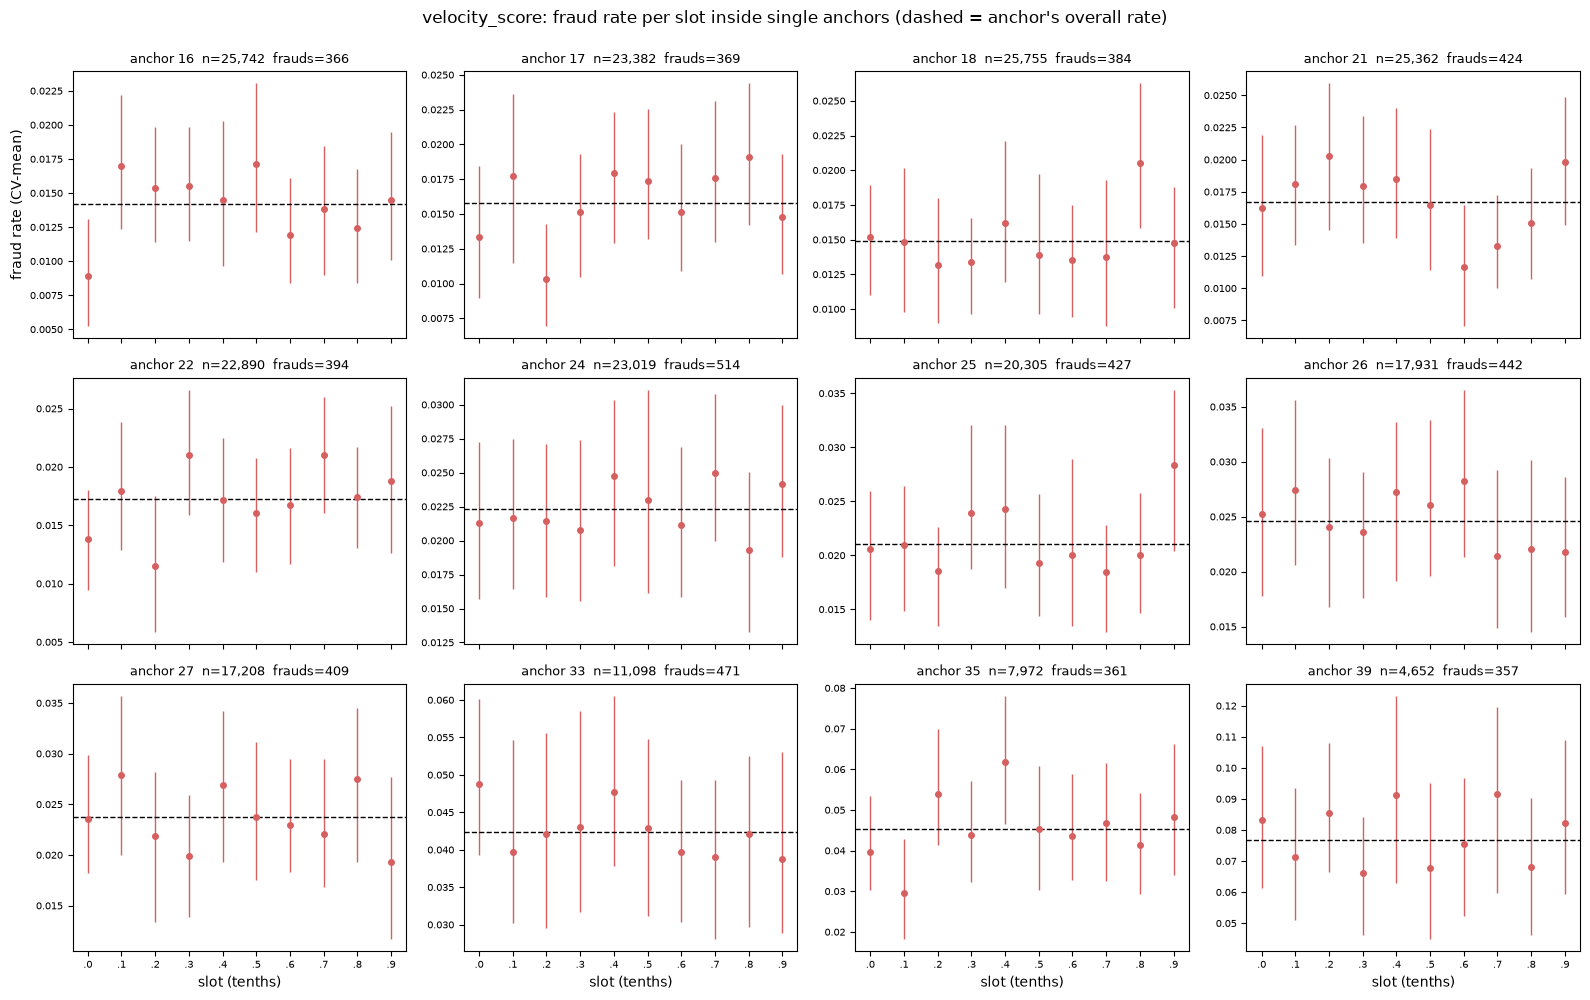

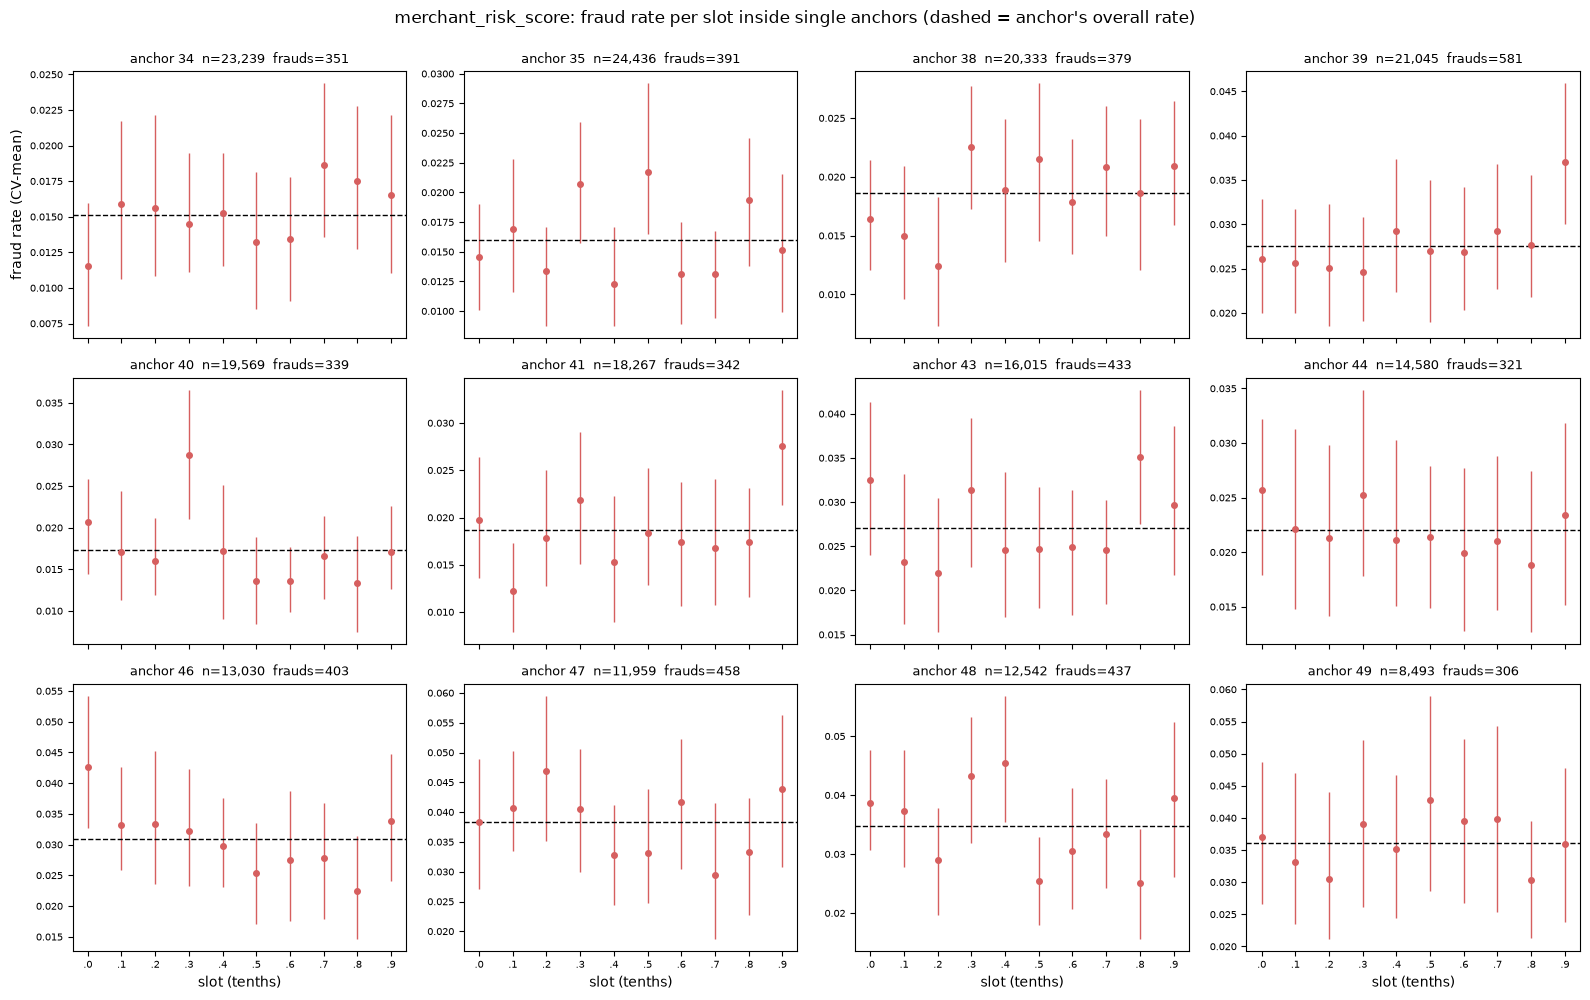

In [3]:
# View 1: per-anchor slot profiles (small multiples), top anchors by fraud count
for column, data in slot_data.items():
    anchor_tot = data["anchors"]
    cells = data["cells"]
    used = (
        anchor_tot[anchor_tot["used"]]
        .sort_values("fraud_total", ascending=False)
        .head(TOP_ANCHORS)
        .sort_index()
    )
    fig, axes = plt.subplots(3, 4, figsize=(16, 10), sharex=True)
    for ax, (a_val, a_row) in zip(axes.ravel(), used.iterrows()):
        sub = cells.loc[a_val]
        n = sub["rows_total"].to_numpy(dtype=np.int64)
        p = sub["cv_mean_rate"].to_numpy()
        draws = rng.binomial(n[:, None], p[:, None], size=(len(sub), B)) / n[:, None]
        lo, hi = np.percentile(draws, [2.5, 97.5], axis=1)
        rate = float(a_row["pooled_rate"])
        ax.errorbar(
            sub.index, p,
            yerr=np.vstack([np.clip(p - lo, 0, None), np.clip(hi - p, 0, None)]),
            fmt="o", ms=4, lw=1, color="#d65f5f", ecolor="#d65f5f",
        )
        ax.axhline(rate, color="black", lw=1, ls="--")
        ax.set_title(
            f"anchor {a_val}  n={int(a_row['rows_total']):,}  frauds={int(a_row['fraud_total'])}",
            fontsize=9,
        )
        ax.set_xticks(SLOTS)
        ax.set_xticklabels([f".{i}" for i in SLOTS], fontsize=7)
        ax.tick_params(labelsize=7)
    axes[0, 0].set_ylabel("fraud rate (CV-mean)")
    for ax in axes[-1]:
        ax.set_xlabel("slot (tenths)")
    fig.suptitle(
        f"{column}: fraud rate per slot inside single anchors "
        f"(dashed = anchor's overall rate)", y=0.995
    )
    fig.tight_layout()
    fig.savefig(plot_dir / f"{column}_anchor_slot_profiles.png", dpi=110)
    plt.show()

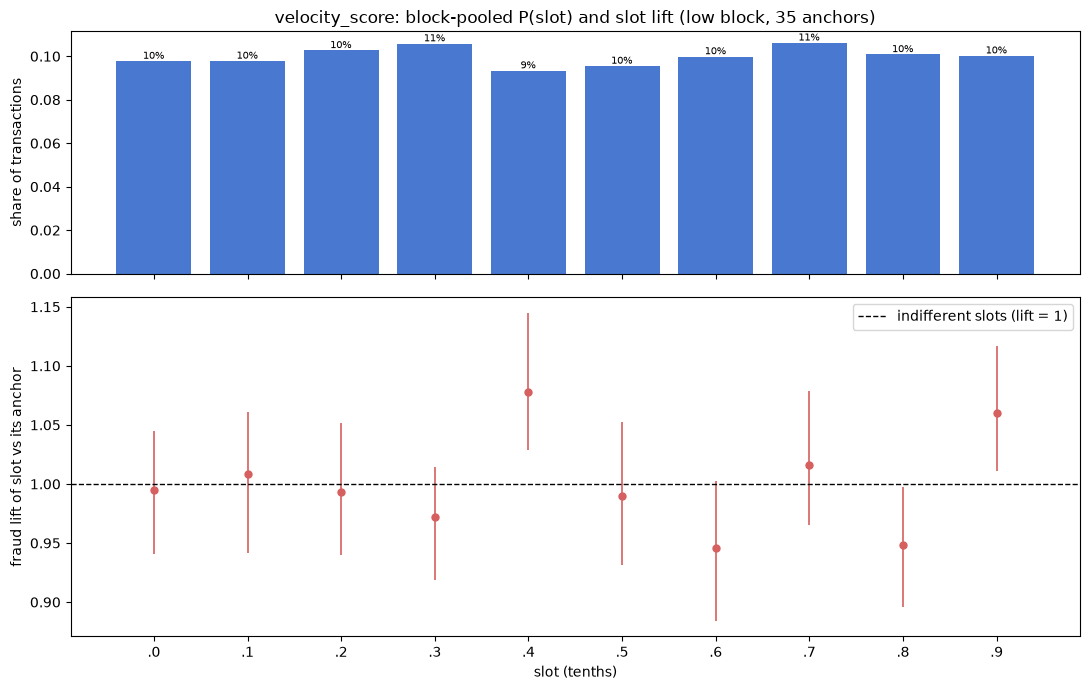

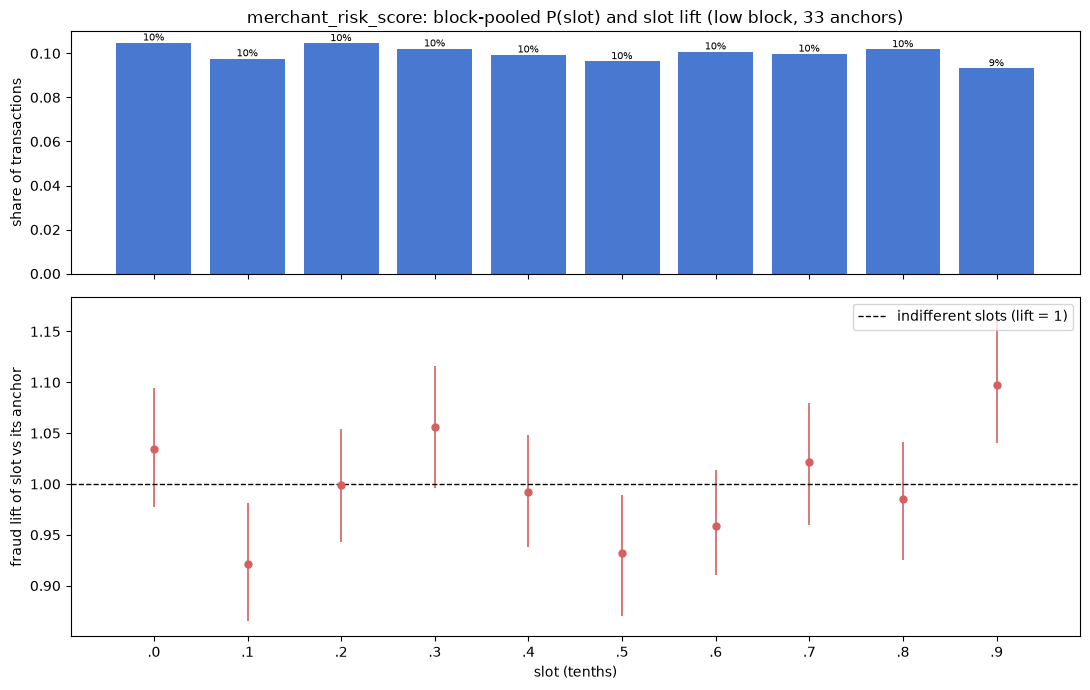

In [4]:
# View 2: block-pooled slot lift with bootstrap CI (+ P(slot) backdrop)
lift_tables = {}
for column, data in slot_data.items():
    cells = data["cells"]
    anchor_tot = data["anchors"]
    used_idx = anchor_tot.index[anchor_tot["used"]]

    n_as = (
        cells["rows_total"].unstack("slot")
        .reindex(index=used_idx, columns=SLOTS).fillna(0)
    ).to_numpy(dtype=np.int64)
    f_as = (
        cells["fraud_total"].unstack("slot")
        .reindex(index=used_idx, columns=SLOTS).fillna(0)
    ).to_numpy(dtype=np.int64)
    cv_as = (
        cells["cv_mean_rate"].unstack("slot")
        .reindex(index=used_idx, columns=SLOTS).fillna(0.0)
    ).to_numpy(dtype=np.float64)
    rate_a = anchor_tot.loc[used_idx, "pooled_rate"].to_numpy(dtype=np.float64)

    obs = f_as.sum(axis=0)
    exp = (n_as * rate_a[:, None]).sum(axis=0)
    lift = obs / exp

    # bootstrap: redraw fraud counts per cell, recompute rates, lifts
    draws = rng.binomial(
        n_as[:, :, None], cv_as[:, :, None], size=(len(used_idx), len(SLOTS), B)
    )
    f_star = draws.sum(axis=0)                                   # (S, B)
    n_a = n_as.sum(axis=1)                                       # (A,)
    anchor_fraud_star = draws.sum(axis=1)                        # (A, B)
    rate_star = anchor_fraud_star / n_a[:, None]                 # (A, B)
    exp_star = (n_as[:, :, None] * rate_star[:, None, :]).sum(axis=0)  # (S, B)
    lift_star = f_star / exp_star
    lo, hi = np.percentile(lift_star, [2.5, 97.5], axis=1)

    lift_tables[column] = pd.DataFrame(
        {"slot": [f".{i}" for i in SLOTS], "rows": n_as.sum(axis=0),
         "obs_frauds": obs, "exp_frauds": exp.round(1),
         "lift": lift.round(3), "ci_lo": lo.round(3), "ci_hi": hi.round(3)}
    )

    fig, (ax_top, ax_bot) = plt.subplots(
        2, 1, figsize=(11, 7), sharex=True, gridspec_kw={"height_ratios": [1, 1.4]}
    )
    share = n_as.sum(axis=0) / n_as.sum()
    ax_top.bar(SLOTS, share, color="#4878d0")
    ax_top.set_ylabel("share of transactions")
    ax_top.set_title(f"{column}: block-pooled P(slot) and slot lift (low block, {len(used_idx)} anchors)")
    for i, s in enumerate(share):
        ax_top.text(SLOTS[i], s, f"{s:.0%}", ha="center", va="bottom", fontsize=7)
    ax_bot.errorbar(
        SLOTS, lift, yerr=np.vstack([np.clip(lift - lo, 0, None), np.clip(hi - lift, 0, None)]),
        fmt="o", ms=5, lw=1.2, color="#d65f5f", ecolor="#d65f5f",
    )
    ax_bot.axhline(1.0, color="black", lw=1, ls="--", label="indifferent slots (lift = 1)")
    ax_bot.set_ylabel("fraud lift of slot vs its anchor")
    ax_bot.set_xlabel("slot (tenths)")
    ax_bot.set_xticks(SLOTS)
    ax_bot.set_xticklabels([f".{i}" for i in SLOTS])
    ax_bot.legend(loc="best")
    fig.tight_layout()
    fig.savefig(plot_dir / f"{column}_slot_lift.png", dpi=110)
    plt.show()

In [5]:
# View 3: permutation homogeneity test (shuffle fraud labels within anchors)
perm_rows = []
for column, data in slot_data.items():
    cells = data["cells"]
    anchor_tot = data["anchors"]
    used_idx = anchor_tot.index[anchor_tot["used"]]

    n_as = (
        cells["rows_total"].unstack("slot")
        .reindex(index=used_idx, columns=SLOTS).fillna(0)
    ).to_numpy(dtype=np.int64)
    f_as = (
        cells["fraud_total"].unstack("slot")
        .reindex(index=used_idx, columns=SLOTS).fillna(0)
    ).to_numpy(dtype=np.int64)
    rate_a = anchor_tot.loc[used_idx, "pooled_rate"].to_numpy(dtype=np.float64)
    frauds_a = f_as.sum(axis=1)

    obs = f_as.sum(axis=0)
    exp = (n_as * rate_a[:, None]).sum(axis=0)
    t_obs = float(((obs - exp) ** 2 / exp).sum())

    n_perm = 200
    null = np.empty(n_perm)
    for b in range(n_perm):
        f_perm = np.stack([
            rng.multivariate_hypergeometric(n_as[a], int(frauds_a[a]))
            for a in range(len(used_idx))
        ])
        obs_p = f_perm.sum(axis=0)
        null[b] = ((obs_p - exp) ** 2 / exp).sum()
    p_value = (1 + int((null >= t_obs).sum())) / (n_perm + 1)
    perm_rows.append({
        "column": column, "anchors": len(used_idx),
        "T_obs": round(t_obs, 1), "null_median": round(float(np.median(null)), 1),
        "null_95pct": round(float(np.percentile(null, 95)), 1),
        "perm_p": p_value,
    })
    print(
        f"{column:22s} T_obs={t_obs:8.1f} | null median={np.median(null):6.1f} "
        f"95th pct={np.percentile(null, 95):7.1f} | permutation p = {p_value:.4f}"
    )
pd.DataFrame(perm_rows)

velocity_score         T_obs=    16.7 | null median=   8.3 95th pct=   18.0 | permutation p = 0.0746
merchant_risk_score    T_obs=    23.1 | null median=   8.7 95th pct=   16.4 | permutation p = 0.0100


,column,anchors,T_obs,null_median,null_95pct,perm_p
0,velocity_score,35,16.7,8.3,18.0,0.074627
1,merchant_risk_score,33,23.1,8.7,16.4,0.009950


## Lift tables

Observed vs expected frauds per slot (expected = slot rows x anchor rate,
summed over the block's anchors).

In [6]:
for column, table in lift_tables.items():
    print(f"\n--- {column} ---")
    display(table)


--- velocity_score ---


,slot,rows,obs_frauds,exp_frauds,lift,ci_lo,ci_hi
0,.0,57930,1026,1031.1,0.995,0.941,1.045
1,.1,57960,1032,1023.1,1.009,0.941,1.061
2,.2,60848,1014,1020.6,0.994,0.940,1.052
3,.3,62696,1055,1085.1,0.972,0.919,1.014
4,.4,55331,1048,972.5,1.078,1.029,1.145
5,.5,56586,952,961.5,0.990,0.932,1.052
6,.6,59167,991,1047.4,0.946,0.884,1.002
7,.7,62907,1070,1053.4,1.016,0.965,1.079
8,.8,59750,1009,1063.6,0.949,0.896,0.998
9,.9,59392,1077,1015.7,1.060,1.011,1.117



--- merchant_risk_score ---


,slot,rows,obs_frauds,exp_frauds,lift,ci_lo,ci_hi
0,.0,57197,980,947.4,1.034,0.977,1.094
1,.1,53289,807,875.6,0.922,0.865,0.982
2,.2,57055,897,898.3,0.999,0.943,1.054
3,.3,55735,954,903.8,1.056,0.997,1.116
4,.4,54240,859,865.7,0.992,0.938,1.048
5,.5,52590,790,847.2,0.933,0.870,0.989
6,.6,54994,835,870.6,0.959,0.911,1.014
7,.7,54443,892,873.0,1.022,0.960,1.080
8,.8,55560,839,851.9,0.985,0.925,1.042
9,.9,50849,908,827.6,1.097,1.040,1.168


In [7]:
# descriptive summary only - no conclusions yet
rows = []
for column, data in slot_data.items():
    anchor_tot = data["anchors"]
    used = anchor_tot[anchor_tot["used"]]
    table = lift_tables[column]
    strongest = table.loc[table["lift"].idxmax()]
    weakest = table.loc[table["lift"].idxmin()]
    perm = next(r for r in perm_rows if r["column"] == column)
    rows.append({
        "column": column,
        "anchors": len(used),
        "rows": int(used["rows_total"].sum()),
        "frauds": int(used["fraud_total"].sum()),
        "max lift": f"{strongest['lift']} at slot {strongest['slot']} [{strongest['ci_lo']}, {strongest['ci_hi']}]",
        "min lift": f"{weakest['lift']} at slot {weakest['slot']} [{weakest['ci_lo']}, {weakest['ci_hi']}]",
        "perm_p": perm["perm_p"],
    })
pd.DataFrame(rows)

,column,anchors,rows,frauds,max lift,min lift,perm_p
0,velocity_score,35,592567,10274,"1.078 at slot .4 [1.029, 1.145]","0.946 at slot .6 [0.884, 1.002]",0.074627
1,merchant_risk_score,33,545952,8761,"1.097 at slot .9 [1.04, 1.168]","0.922 at slot .1 [0.865, 0.982]",0.009950


## Interpretation

Written 2026-11-22, after review and the follow-up stability notebook.

- Inside anchors, the decimals carry a small signal on merchant_risk only:
  an alternating tilt (.9 up ~10%, .3/.0 up, .1/.5 down), block-level
  permutation p = 0.010. Velocity shows same-sized effects but p = 0.075 -
  not resolved. Effects are +-10% rate modulations, nowhere near gradient
  scale.
- Per-anchor panels are flat within error bars: whatever tilt exists is
  shared across anchors, not an anchor-specific phenomenon.
- Established since: the tilt replicates across folds and one shared tilt
  explains every anchor (slot_tilt_stability.ipynb), and encoding it as
  atilt features on top of anchor_v2 was FLAT (+0.00006, anchor_v2t).
  Reading: the decimals matter to the model only through the exact value's
  rate (arate10) - the tilt is a compressed restatement of it.